Importing the dependencies

In [47]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
)
from sklearn.model_selection import (
    ParameterGrid,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# imblearn's Pipeline applies SMOTE only while fitting (never on validation/test data)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import joblib

warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')

RANDOM_STATE = 42

print('Environment Ready.')

Environment Ready.


1. Load the Online Fraud Dataset

In [2]:
data = pd.read_csv('Data/onlinefraud.csv', nrows=50000)

print('Data shape:', data.shape)
print('\nColumns:')
print(data.columns.tolist())

data.head()

Data shape: (50000, 11)

Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
print('Data types and non-null counts:')
data.info()

print('\nTarget distribution:')
print(data['isFraud'].value_counts())
print('\nTarget percentage:')
print((data['isFraud'].value_counts(normalize=True) * 100).round(2))

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            50000 non-null  int64  
 1   type            50000 non-null  str    
 2   amount          50000 non-null  float64
 3   nameOrig        50000 non-null  str    
 4   oldbalanceOrg   50000 non-null  float64
 5   newbalanceOrig  49998 non-null  float64
 6   nameDest        50000 non-null  str    
 7   oldbalanceDest  50000 non-null  float64
 8   newbalanceDest  50000 non-null  float64
 9   isFraud         50000 non-null  int64  
 10  isFlaggedFraud  50000 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 4.2 MB

Target distribution:
isFraud
0    49900
1      100
Name: count, dtype: int64

Target percentage:
isFraud
0    99.8
1     0.2
Name: proportion, dtype: float64


2. Data Quality Audit and Cleaning

In [4]:
df = data.copy()

type_mapping = {
    'PAYMENT': 0,
    'TRANSFER': 1,
    'CASH_OUT': 2,
    'DEBIT': 3,
    'CASH_IN': 4,
}
df['type'] = df['type'].map(type_mapping)

# Any transaction type that is not in the mapping would silently become NaN
print('Unmapped transaction types:', int(df['type'].isna().sum()))

df.head()

Unmapped transaction types: 0


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,0,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,0,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,1,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,2,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,0,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [48]:
label_encoder = LabelEncoder()
for col in data.select_dtypes(include=['object']).columns:
    data[col] = label_encoder.fit_transform(data[col])

In [5]:
quality_report = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(3),
    'unique_values': df.nunique(),
}).sort_values('missing_count', ascending=False)

quality_report

,dtype,missing_count,missing_pct,unique_values
newbalanceOrig,float64,2,0.004,23920
type,int64,0,0.000,5
step,int64,0,0.000,9
amount,float64,0,0.000,49786
nameOrig,str,0,0.000,50000
oldbalanceOrg,float64,0,0.000,30194
nameDest,str,0,0.000,28499
oldbalanceDest,float64,0,0.000,24444
newbalanceDest,float64,0,0.000,9168
isFraud,int64,0,0.000,2


In [6]:
df = df.dropna(subset=['newbalanceOrig'])

In [7]:
print('Cleaned Shape:', df.shape)
print('Remaining missing values:', int(df.isna().sum().sum()))
df.head()

Cleaned Shape: (49998, 11)
Remaining missing values: 0


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,0,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,0,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,1,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,2,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,0,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Outlier detection and handling

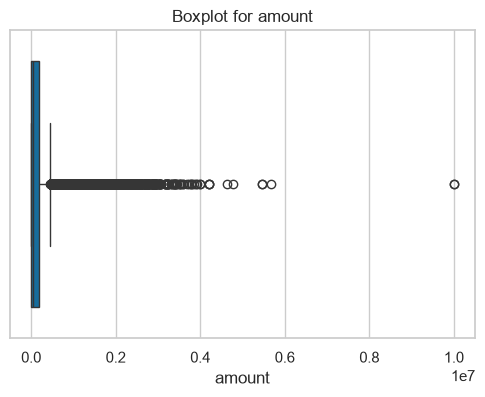

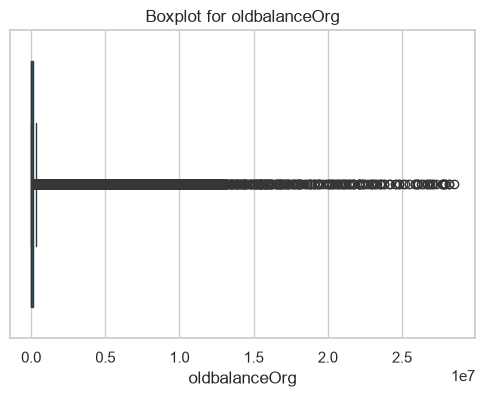

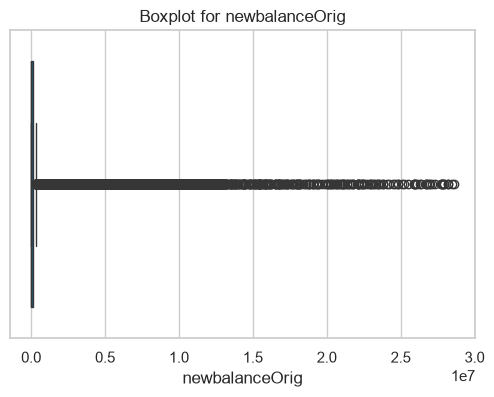

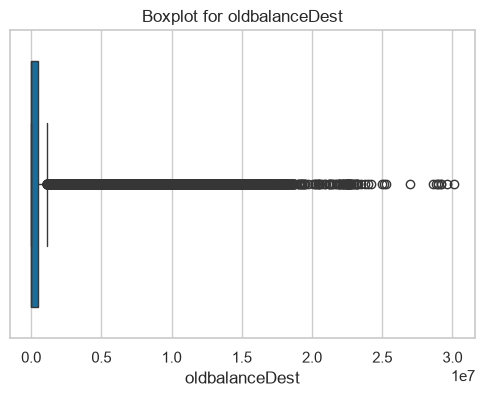

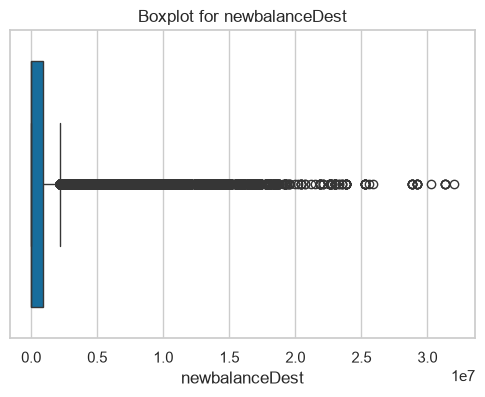

In [8]:
df.columns = df.columns.str.strip()

# Only genuinely continuous columns are checked/clipped. 'step' (hour), 'type' (category code),
# the ID columns and the target are not clipped: clipping them corrupts the data
# (e.g. it merged steps 1-3 into step 4 and could change transaction types).
OUTLIER_COLS = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

for col in OUTLIER_COLS:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot for {col}')
    plt.show()

In [9]:
def handle_outliers_clip(frame, cols):
    """Return a COPY of frame with `cols` clipped to the 1.5*IQR fences."""
    out = frame.copy()
    for col in cols:
        Q1 = out[col].quantile(0.25)
        Q3 = out[col].quantile(0.75)
        IQR = Q3 - Q1
        out[col] = out[col].clip(lower=Q1 - 1.5 * IQR, upper=Q3 + 1.5 * IQR)
    return out

# df itself stays untouched, so the before/after plots below are a real comparison
data_no_outliers_clip = handle_outliers_clip(df, OUTLIER_COLS)
print(data_no_outliers_clip['isFraud'].value_counts())

isFraud
0    49898
1      100
Name: count, dtype: int64


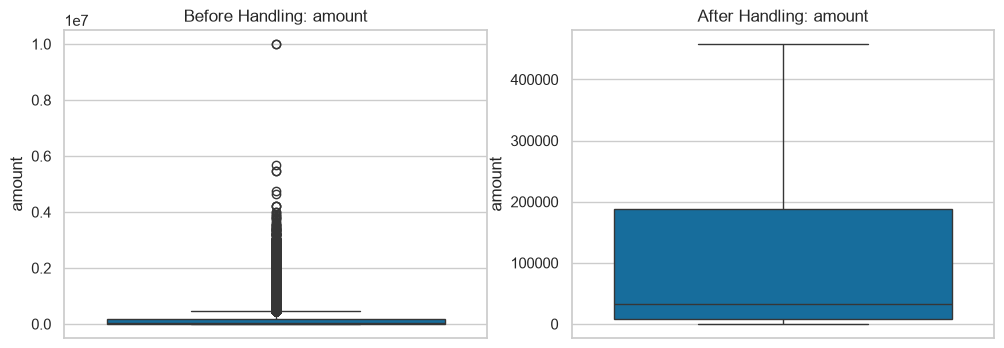

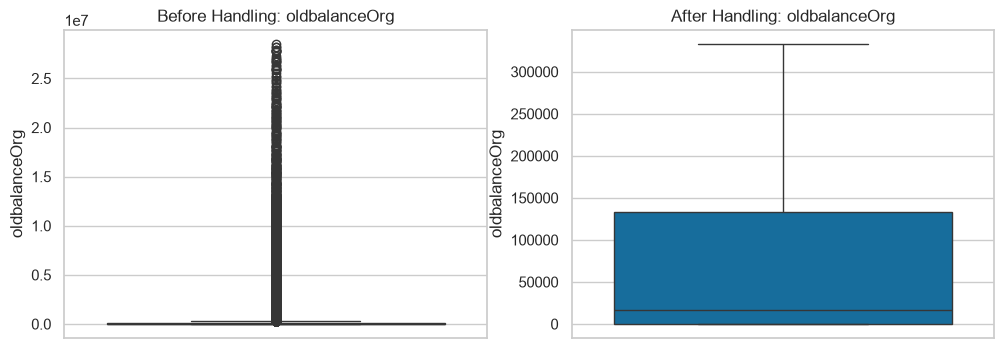

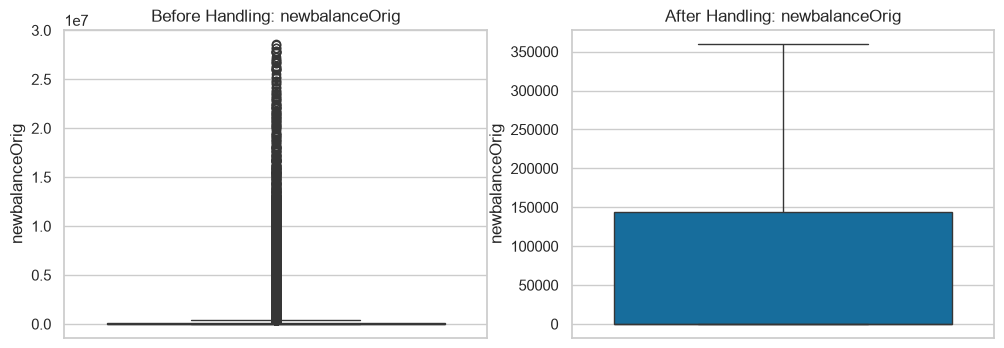

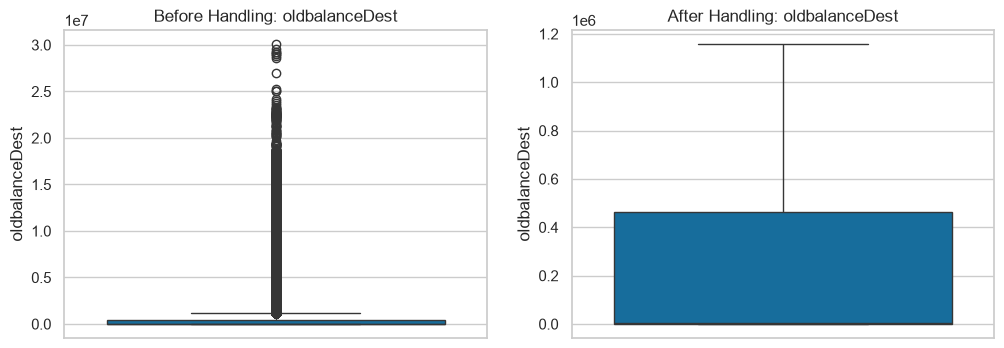

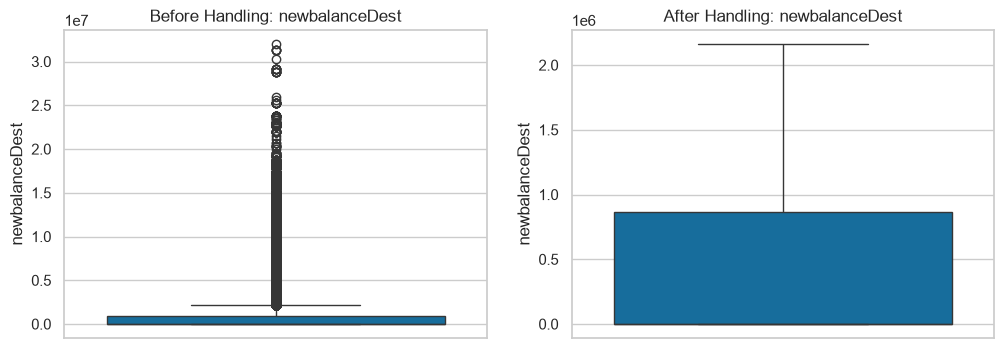

In [10]:
for col in OUTLIER_COLS:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(y=df[col], ax=axes[0])
    axes[0].set_title(f'Before Handling: {col}')

    sns.boxplot(y=data_no_outliers_clip[col], ax=axes[1])
    axes[1].set_title(f'After Handling: {col}')

    plt.show()

3. Exploratory Data Analysis (EDA)

In [11]:
print(df.shape)
print(df.size)
print(df.describe())
df.info()

(49998, 11)
549978
               step          type        amount  oldbalanceOrg  \
count  49998.000000  49998.000000  4.999800e+04   4.999800e+04   
mean       7.454058      1.402036  1.562664e+05   7.333378e+05   
std        2.056272      1.490506  3.244005e+05   2.202422e+06   
min        1.000000      0.000000  6.300000e-01   0.000000e+00   
25%        7.000000      0.000000  7.734975e+03   0.000000e+00   
50%        8.000000      1.000000  3.341482e+04   1.703272e+04   
75%        9.000000      2.000000  1.878346e+05   1.331849e+05   
max        9.000000      4.000000  1.000000e+07   2.850000e+07   

       newbalanceOrig  oldbalanceDest  newbalanceDest       isFraud  \
count    4.999800e+04    4.999800e+04    4.999800e+04  49998.000000   
mean     7.473080e+05    8.445121e+05    1.164511e+06      0.002000   
std      2.240010e+06    2.433517e+06    2.915487e+06      0.044678   
min      0.000000e+00    0.000000e+00    0.000000e+00      0.000000   
25%      0.000000e+00    0.0000

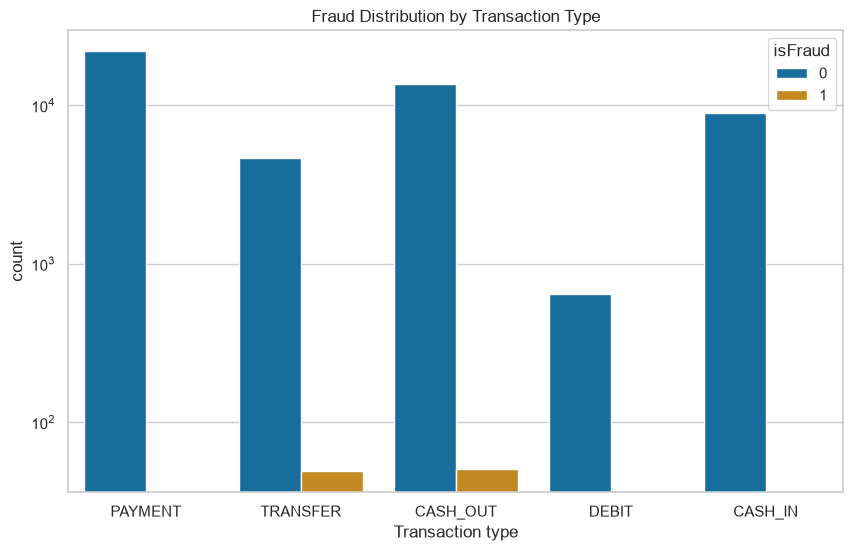

In [12]:
# Fraud Transaction Analysis
type_labels = {v: k for k, v in type_mapping.items()}
plot_df = df.assign(type_name=df['type'].map(type_labels))
order = [name for name in type_mapping if name in set(plot_df['type_name'])]

plt.figure(figsize=(10, 6))
ax = sns.countplot(x='type_name', hue='isFraud', data=plot_df, order=order)
ax.set_yscale('log')   # fraud is ~0.2% of rows, so a linear axis hides it
ax.set_xlabel('Transaction type')
plt.title('Fraud Distribution by Transaction Type')
plt.show()

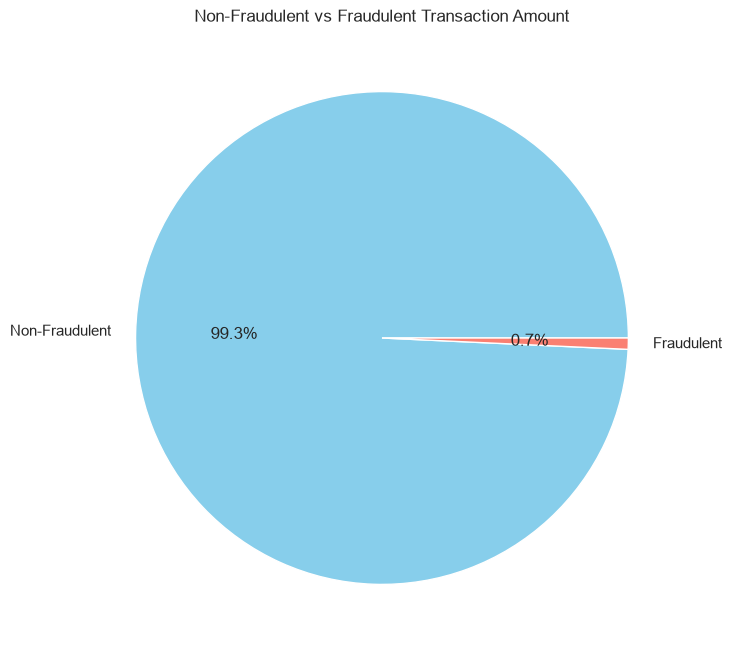

In [13]:
# Pie chart: share of total transaction amount, fraudulent vs non-fraudulent
fraud_amounts = df.groupby('isFraud')['amount'].sum()
pie_labels = ['Non-Fraudulent' if i == 0 else 'Fraudulent' for i in fraud_amounts.index]

plt.figure(figsize=(8, 8))
plt.pie(fraud_amounts, labels=pie_labels, autopct='%1.1f%%', colors=['skyblue', 'salmon'][:len(fraud_amounts)])
plt.title('Non-Fraudulent vs Fraudulent Transaction Amount')
plt.show()

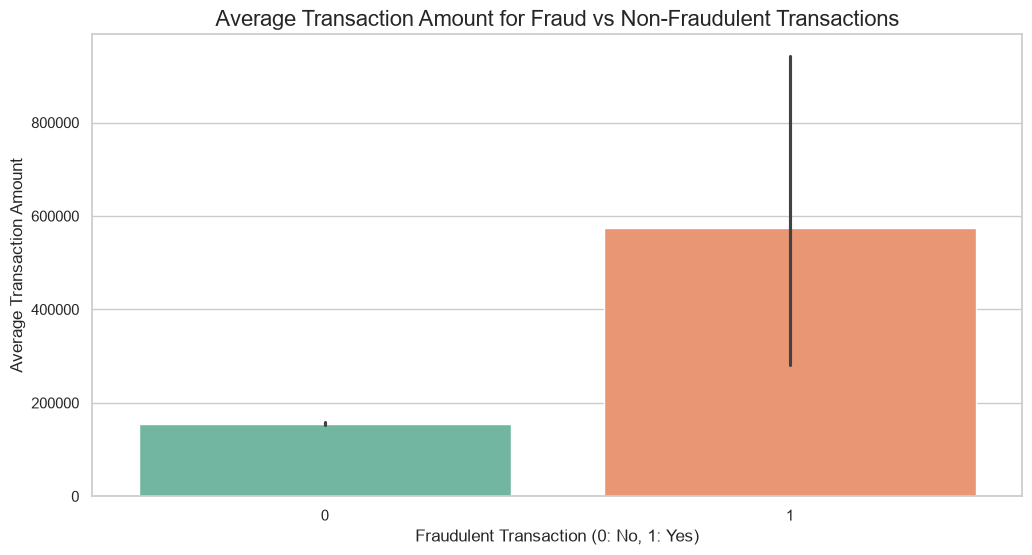

In [14]:
# Bar plot of average transaction amount for fraud vs non-fraud
plt.figure(figsize=(12, 6))
sns.barplot(x='isFraud', y='amount', hue='isFraud', data=df, palette='Set2', legend=False)
plt.title('Average Transaction Amount for Fraud vs Non-Fraudulent Transactions', fontsize=16)
plt.xlabel('Fraudulent Transaction (0: No, 1: Yes)', fontsize=12)
plt.ylabel('Average Transaction Amount', fontsize=12)
plt.show()

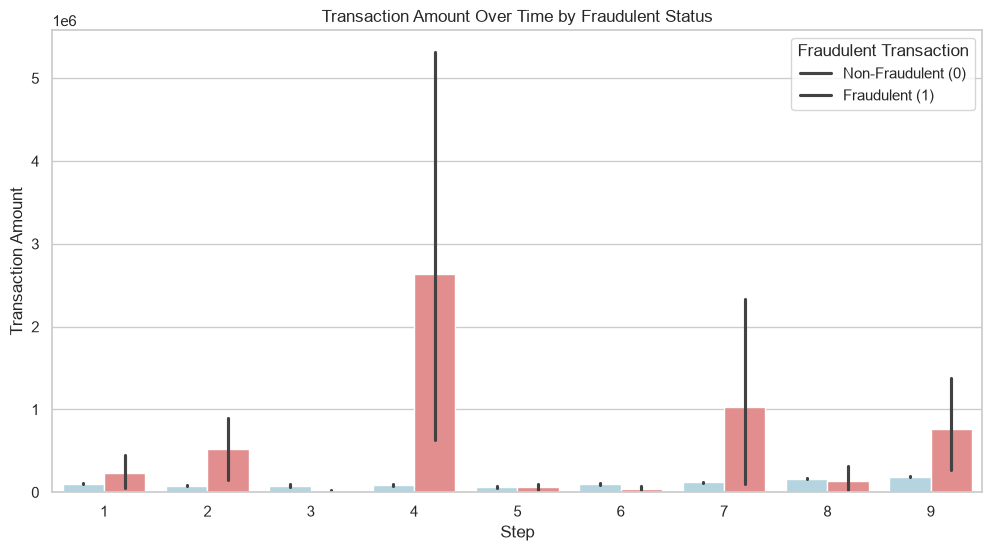

In [15]:
# Average transaction amount over time (step), fraud vs non-fraud
plt.figure(figsize=(12, 6))
sns.barplot(x='step', y='amount', data=df, hue='isFraud', palette={0: 'lightblue', 1: 'lightcoral'})
plt.title('Transaction Amount Over Time by Fraudulent Status')
plt.xlabel('Step')
plt.ylabel('Transaction Amount')
plt.legend(title='Fraudulent Transaction', labels=['Non-Fraudulent (0)', 'Fraudulent (1)'])
plt.show()

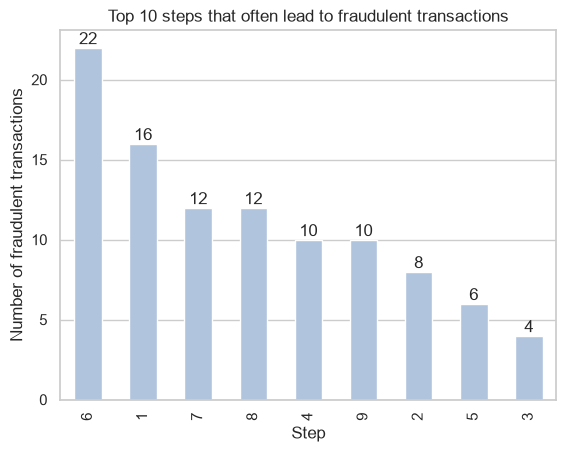

Step 6 has the most fraudulent transactions (22).


In [16]:
# Top 10 steps (hours) where fraudulent transactions are most frequent
fraud_steps = df.loc[df['isFraud'] == 1, 'step'].value_counts().head(10)

ax = fraud_steps.plot(kind='bar', color='lightsteelblue')
for container in ax.containers:
    ax.bar_label(container)
plt.title('Top 10 steps that often lead to fraudulent transactions')
plt.ylabel('Number of fraudulent transactions')
plt.xlabel('Step')
plt.grid(axis='x')
plt.show()

print(f'Step {fraud_steps.index[0]} has the most fraudulent transactions ({fraud_steps.iloc[0]}).')

The step with the highest number of fraudulent transactions is printed under the chart above (computed from the data, so it stays correct if the data or sample size changes).

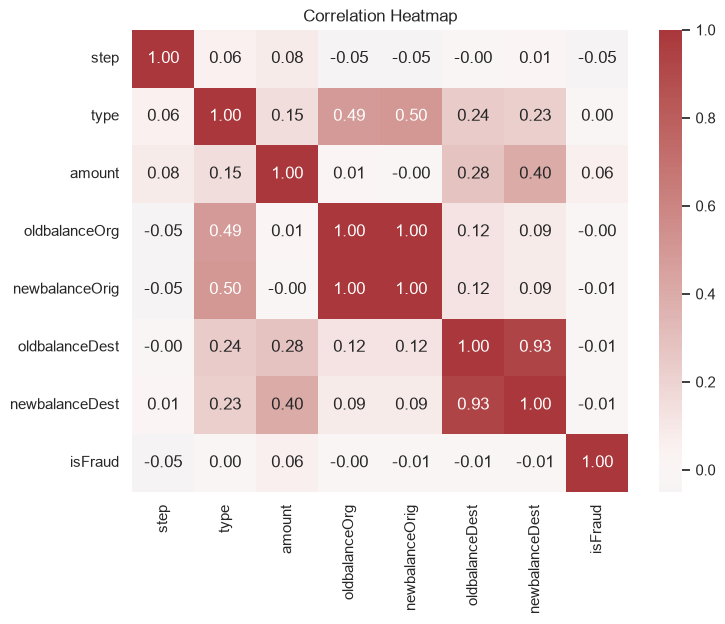

In [17]:
# Correlation heatmap (ID columns and the constant isFlaggedFraud column carry no information)
corr_df = df.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud'])

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, cmap='vlag', center=0, fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

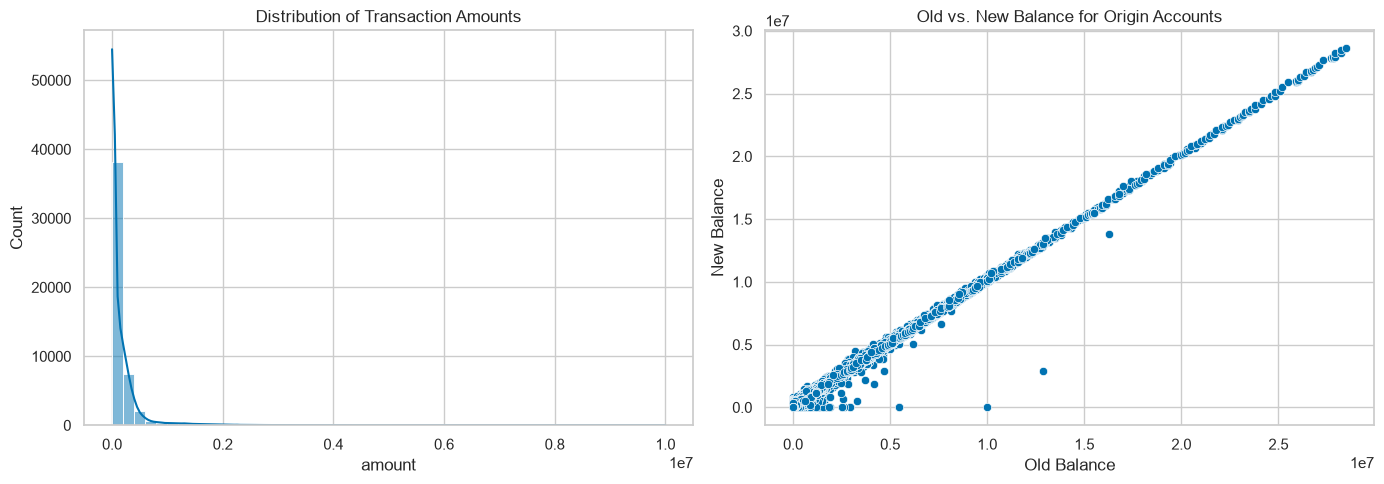

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of transaction amounts
sns.histplot(df['amount'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Transaction Amounts')

# Balance before vs. after transactions for origin accounts
sns.scatterplot(x=df['oldbalanceOrg'], y=df['newbalanceOrig'], ax=axes[1])
axes[1].set_title('Old vs. New Balance for Origin Accounts')
axes[1].set_xlabel('Old Balance')
axes[1].set_ylabel('New Balance')

plt.tight_layout()
plt.show()

isFraud
0    49898
1      100
Name: count, dtype: int64


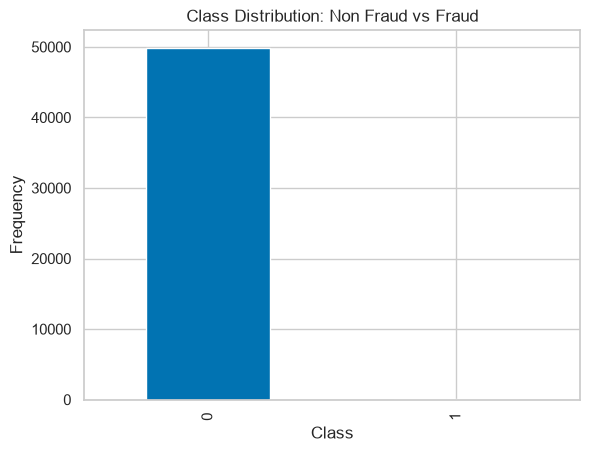

In [19]:
# Check for class distribution
print(df['isFraud'].value_counts())

# Visualize the class imbalance
df['isFraud'].value_counts().plot(kind='bar')
plt.title('Class Distribution: Non Fraud vs Fraud')
plt.xlabel('Class')
plt.ylabel('Frequency')
plt.show()

Define the ML Problem

In [20]:
target = 'isFraud'
drop_cols = ['isFraud', 'nameOrig', 'nameDest', 'isFlaggedFraud']

X = df.drop(columns=drop_cols)
y = df[target]          # 1-D Series (not a one-column DataFrame)

categorical_features = ['type']
numeric_features = [c for c in X.columns if c not in categorical_features]

In [21]:
X.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
0,1,0,9839.64,170136.0,160296.36,0.0,0.0
1,1,0,1864.28,21249.0,19384.72,0.0,0.0
2,1,1,181.00,181.0,0.00,0.0,0.0
3,1,2,181.00,181.0,0.00,21182.0,0.0
4,1,0,11668.14,41554.0,29885.86,0.0,0.0


In [22]:
y.head()

0    0
1    0
2    1
3    1
4    0
Name: isFraud, dtype: int64

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE,
)

print('Training rows :', X_train.shape[0])
print('Test Rows :', X_test.shape[0])
print('Numeric Features :', numeric_features)
print('Categorical Features :', categorical_features)
print('\nTrain isFraud rate:', round(y_train.mean(), 4))
print('Test isFraud rate:', round(y_test.mean(), 4))

Training rows : 37498
Test Rows : 12500
Numeric Features : ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Categorical Features : ['type']

Train isFraud rate: 0.002
Test isFraud rate: 0.002


In [24]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

# 'type' is a category code, not a quantity, so it is one-hot encoded instead of scaled
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

print('Preprocessing pipeline ready')

Preprocessing pipeline ready


Initial Modeling

In [25]:
def make_classifiers():
    return {
        'Random Forest Classifier': RandomForestClassifier(n_estimators=47, random_state=RANDOM_STATE),
        'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
        'SVM': SVC(kernel='linear', probability=True, random_state=RANDOM_STATE),  # slow on large data
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'Naive Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5),
        'AdaBoost': AdaBoostClassifier(n_estimators=50, random_state=RANDOM_STATE, learning_rate=0.3),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, random_state=RANDOM_STATE),
        # binary problem -> 'logloss' (not 'mlogloss', which is for multi-class)
        'XGBoost': XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                 random_state=RANDOM_STATE, eval_metric='logloss'),
    }

classifiers = make_classifiers()

In [26]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    """Fit `model`, then score it on the (untouched) test set."""
    model.fit(X_tr, y_tr)
    y_train_pred = model.predict(X_tr)
    y_test_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    return {
        'Model': name,
        'Train Accuracy': accuracy_score(y_tr, y_train_pred) * 100,
        'Test Accuracy': accuracy_score(y_te, y_test_pred) * 100,
        'Precision': precision_score(y_te, y_test_pred, zero_division=0) * 100,
        'Recall': recall_score(y_te, y_test_pred, zero_division=0) * 100,
        'F1': f1_score(y_te, y_test_pred, zero_division=0) * 100,
        'Roc_Auc': roc_auc_score(y_te, y_proba) * 100,
        'PR_Auc': average_precision_score(y_te, y_proba) * 100,   # more informative than accuracy for rare fraud
        'Confusion Matrix': confusion_matrix(y_te, y_test_pred).tolist(),
    }

In [27]:
results = []

for name, clf in classifiers.items():
    # scaling + encoding happen inside the pipeline, fitted on the training data only
    model = Pipeline(steps=[('preprocess', preprocessor), ('clf', clf)])
    results.append(evaluate_model(name, model, X_train, y_train, X_test, y_test))

initial_modeling = pd.DataFrame(results)
print('\nInitial Model Performance:')
initial_modeling


Initial Model Performance:


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc,Confusion Matrix
0,Random Forest Classifier,100.000000,99.952,95.238095,80.0,86.956522,99.987174,92.056915,"[[12474, 1], [5, 20]]"
1,Logistic Regression,99.807990,99.816,100.000000,8.0,14.814815,98.773547,26.356448,"[[12475, 0], [23, 2]]"
2,SVM,99.802656,99.816,100.000000,8.0,14.814815,97.420120,28.193402,"[[12475, 0], [23, 2]]"
3,KNN,99.818657,99.792,42.857143,12.0,18.750000,71.752465,10.696592,"[[12471, 4], [22, 3]]"
4,Naive Bayes,64.214091,64.896,0.566508,100.0,1.126634,95.538437,2.328198,"[[8087, 4388], [0, 25]]"
5,Decision Tree,99.823991,99.784,33.333333,8.0,12.903226,96.942525,22.095856,"[[12471, 4], [23, 2]]"
6,AdaBoost,99.799989,99.808,100.000000,4.0,7.692308,99.406493,35.846420,"[[12475, 0], [24, 1]]"
7,Gradient Boosting,99.941330,99.856,60.000000,84.0,70.000000,99.858918,54.199676,"[[12461, 14], [4, 21]]"
8,XGBoost,99.941330,99.960,91.666667,88.0,89.795918,99.991984,97.032444,"[[12473, 2], [3, 22]]"


Handling Imbalanced Data

In [28]:
# Check for class imbalance (fraud vs non-fraud) in the training data
print(y_train.value_counts())

isFraud
0    37423
1       75
Name: count, dtype: int64


SMOTE (Synthetic Minority Over-sampling Technique)

In [50]:
# SMOTE must be applied AFTER the train/test split and to the training data only.
# (Resampling before the split puts synthetic copies of test rows in the training
#  set and makes the test metrics look better than they really are.)
prep_demo = clone(preprocessor)
X_train_prepared = prep_demo.fit_transform(X_train)

scaler = StandardScaler()
X_Scaled = scaler.fit_transform(X)

smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_prepared, y_train)

print('Before SMOTE:', y_train.value_counts().to_dict())
print('After SMOTE :', pd.Series(y_train_res).value_counts().to_dict())

Before SMOTE: {0: 37423, 1: 75}
After SMOTE : {0: 37423, 1: 37423}


In [30]:
print(f'Train X shape: {X_train.shape}  (original, un-resampled)')
print(f'Train y shape: {y_train.shape}')
print(f'Test X shape: {X_test.shape}')
print(f'Test y shape: {y_test.shape}')
print(f'Resampled train X shape: {X_train_res.shape}')
print(f'Resampled train y shape: {y_train_res.shape}')

Train X shape: (37498, 7)  (original, un-resampled)
Train y shape: (37498,)
Test X shape: (12500, 7)
Test y shape: (12500,)
Resampled train X shape: (74846, 11)
Resampled train y shape: (74846,)


In [31]:
print(len(X_train), len(y_train))
print(len(X_test), len(y_test))
print(X_train_res.shape[0], len(y_train_res))

37498 37498
12500 12500
74846 74846


In [32]:
# Same models, but SMOTE is applied inside the pipeline so it only ever touches training data.
# Note: use_label_encoder was removed from XGBoost and is no longer passed.
classifiers = make_classifiers()
classifiers['Gradient Boosting'] = GradientBoostingClassifier(n_estimators=600, learning_rate=0.05, random_state=RANDOM_STATE)

In [33]:
results = []

for name, clf in classifiers.items():
    model = ImbPipeline(steps=[
        ('preprocess', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', clf),
    ])
    results.append(evaluate_model(name, model, X_train, y_train, X_test, y_test))

over_modeling = pd.DataFrame(results)
print('\nModel Performance after Over Sampling:')
over_modeling


Model Performance after Over Sampling:


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc,Confusion Matrix
0,Random Forest Classifier,99.997333,99.832,54.347826,100.0,70.422535,99.975311,88.137648,"[[12454, 21], [0, 25]]"
1,Logistic Regression,91.175529,91.352,2.260398,100.0,4.420866,99.214108,38.723846,"[[11394, 1081], [0, 25]]"
2,SVM,93.148968,93.336,2.913753,100.0,5.662514,99.340762,38.278298,"[[11642, 833], [0, 25]]"
3,KNN,98.754600,98.136,5.932203,56.0,10.727969,80.986293,5.927942,"[[12253, 222], [11, 14]]"
4,Naive Bayes,66.011521,66.624,0.595664,100.0,1.184273,96.450982,3.098829,"[[8303, 4172], [0, 25]]"
5,Decision Tree,92.362259,92.584,2.626050,100.0,5.117707,98.987575,9.735370,"[[11548, 927], [0, 25]]"
6,AdaBoost,85.079204,85.112,1.325557,100.0,2.616431,99.406974,18.973341,"[[10614, 1861], [0, 25]]"
7,Gradient Boosting,99.349299,99.264,21.367521,100.0,35.211268,99.991343,95.865337,"[[12383, 92], [0, 25]]"
8,XGBoost,97.653208,97.864,8.561644,100.0,15.772871,99.974028,91.077372,"[[12208, 267], [0, 25]]"


Hyperparameter Tuning

In [34]:
classifiers = {
    'Random Forest Classifier': RandomForestClassifier(random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
    'SVM': SVC(probability=True, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'AdaBoost': AdaBoostClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
}

In [35]:
# Keys must match the names in `classifiers` exactly; 'clf__' routes each parameter to the
# classifier step of the pipeline.
param_grids = {
    'Random Forest Classifier': {
        'clf__n_estimators': [200, 500],
        'clf__max_depth': [10, 15, None],
        'clf__min_samples_split': [6, 8],
        'clf__min_samples_leaf': [3, 4],
        'clf__max_features': ['sqrt'],
        'clf__bootstrap': [True],
    },
    'Logistic Regression': {
        'clf__C': [0.1, 1, 10],
    },
    'SVM': {
        'clf__C': [1, 10],
        'clf__kernel': ['rbf'],
    },
    'KNN': {
        'clf__n_neighbors': [3, 5],
    },
    'Naive Bayes': {
        'clf__var_smoothing': [1e-9],
    },
    'Decision Tree': {
        'clf__max_depth': [None, 10, 20],
        'clf__min_samples_split': [5, 10],
    },
    'AdaBoost': {
        'clf__n_estimators': [100],
        'clf__learning_rate': [0.1],
    },
    'Gradient Boosting': {
        'clf__n_estimators': [100],
        'clf__learning_rate': [0.1],
    },
    'XGBoost': {
        'clf__n_estimators': [100],
        'clf__learning_rate': [0.1],
        'clf__max_depth': [5],
    },
}

In [36]:
n_iter_search = 20
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

best_models = {}
results = []

for name, clf in classifiers.items():
    print(f'\nHyperparameter tuning for {name} using RandomizedSearchCV...')

    grid = param_grids.get(name, {})
    if not grid:
        print('  no parameter grid defined - skipped')
        continue

    # RandomizedSearchCV cannot sample more combinations than the grid contains
    n_iter = min(n_iter_search, len(ParameterGrid(grid)))

    pipe = ImbPipeline(steps=[
        ('preprocess', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),   # re-fitted inside every CV fold
        ('clf', clf),
    ])

    random_search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=grid,
        n_iter=n_iter,
        scoring='f1',          # accuracy is meaningless with 0.2% fraud
        cv=cv,
        n_jobs=-1,
        verbose=1,
        random_state=RANDOM_STATE,
    )
    random_search.fit(X_train, y_train)

    best = random_search.best_estimator_
    best_models[name] = best
    print(f'Best Parameters for {name}: {random_search.best_params_}')

    y_train_pred = best.predict(X_train)
    y_pred = best.predict(X_test)
    y_proba = best.predict_proba(X_test)[:, 1]

    train_accuracy = accuracy_score(y_train, y_train_pred)
    hyper_accuracy = accuracy_score(y_test, y_pred)
    print(f'Training Accuracy for {name}: {train_accuracy * 100:.2f}%')
    print(f'Test Accuracy for {name}: {hyper_accuracy * 100:.2f}%\n')

    results.append({
        'Model': name,
        'Best Parameters': random_search.best_params_,
        'CV F1': random_search.best_score_ * 100,
        'Training Accuracy': train_accuracy * 100,
        'Test Accuracy': hyper_accuracy * 100,
        'Precision': precision_score(y_test, y_pred, zero_division=0) * 100,
        'Recall': recall_score(y_test, y_pred, zero_division=0) * 100,
        'Test F1': f1_score(y_test, y_pred, zero_division=0) * 100,
        'Roc_Auc': roc_auc_score(y_test, y_proba) * 100,
    })

hyper_modeling = pd.DataFrame(results)

print('\nModel Performance After Randomized Search')
hyper_modeling


Hyperparameter tuning for Random Forest Classifier using RandomizedSearchCV...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters for Random Forest Classifier: {'clf__n_estimators': 200, 'clf__min_samples_split': 8, 'clf__min_samples_leaf': 3, 'clf__max_features': 'sqrt', 'clf__max_depth': None, 'clf__bootstrap': True}
Training Accuracy for Random Forest Classifier: 99.92%
Test Accuracy for Random Forest Classifier: 99.80%


Hyperparameter tuning for Logistic Regression using RandomizedSearchCV...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best Parameters for Logistic Regression: {'clf__C': 10}
Training Accuracy for Logistic Regression: 92.39%
Test Accuracy for Logistic Regression: 92.67%


Hyperparameter tuning for SVM using RandomizedSearchCV...
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best Parameters for SVM: {'clf__kernel': 'rbf', 'clf__C': 10}
Training Accuracy for SVM: 95.12%
Test Accuracy for SVM: 95.20%


Hyperpara

,Model,Best Parameters,CV F1,Training Accuracy,Test Accuracy,Precision,Recall,Test F1,Roc_Auc
0,Random Forest Classifier,"{'clf__n_estimators': 200, 'clf__min_samples_s...",45.855308,99.919996,99.800,50.000000,100.0,66.666667,99.972425
1,Logistic Regression,{'clf__C': 10},4.697820,92.394261,92.672,2.656748,100.0,5.175983,99.324729
2,SVM,"{'clf__kernel': 'rbf', 'clf__C': 10}",5.817002,95.117073,95.200,3.703704,92.0,7.120743,96.570100
3,KNN,{'clf__n_neighbors': 3},10.841512,99.234626,98.488,5.913978,44.0,10.426540,77.188297
4,Naive Bayes,{'clf__var_smoothing': 1e-09},1.157893,66.011521,66.624,0.595664,100.0,1.184273,96.450982
5,Decision Tree,"{'clf__min_samples_split': 5, 'clf__max_depth'...",41.424943,99.986666,99.640,34.375000,88.0,49.438202,93.830701
6,AdaBoost,"{'clf__n_estimators': 100, 'clf__learning_rate...",2.270107,83.679130,83.640,1.207729,100.0,2.386635,99.426854
7,Gradient Boosting,"{'clf__n_estimators': 100, 'clf__learning_rate...",17.487735,98.234573,98.376,10.964912,100.0,19.762846,99.983968
8,XGBoost,"{'clf__n_estimators': 100, 'clf__max_depth': 5...",29.775229,99.229292,99.208,20.161290,100.0,33.557047,99.990701


Find the best model

In [1]:
best_model_row = hyper_modeling.loc[hyper_modeling['Test Accuracy'].idxmax()]
best_model_name = best_model_row['Model']
best_model = best_models[best_model_name]
print(f'\n Best Model Based on Test Accuracy: {best_model_name}')
print(f' Best Test Accuracy: {best_model_row['Test Accuracy']:.2f}%')

NameError: name 'hyper_modeling' is not defined

Model Performance Across Each Stages

In [41]:
merged_df = pd.merge(initial_modeling[['Model', 'Test Accuracy']],
                     over_modeling[['Model', 'Test Accuracy']],
                     on='Model',
                     suffixes=('_Initial', '_Oversampling'))

merged_df = pd.merge(merged_df,
                     hyper_modeling[['Model', 'Test Accuracy']],
                     on='Model')

merged_df.columns = ['Model',
                     'Accuracy_Initial',
                     'Accuracy_Oversampling',
                     'Accuracy_Hyperparameter_Tuning'
                     ]

print('\n Model Performance Across Each Stage:')
merged_df


 Model Performance Across Each Stage:


,Model,Accuracy_Initial,Accuracy_Oversampling,Accuracy_Hyperparameter_Tuning
0,Random Forest Classifier,99.952,99.832,99.800
1,Logistic Regression,99.816,91.352,92.672
2,SVM,99.816,93.336,95.200
3,KNN,99.792,98.136,98.488
4,Naive Bayes,64.896,66.624,66.624
5,Decision Tree,99.784,92.584,99.640
6,AdaBoost,99.808,85.112,83.640
7,Gradient Boosting,99.856,99.264,98.376
8,XGBoost,99.960,97.864,99.208


Final Random forest Model

Train Accuracy: 0.9990
Test Accuracy; 0.9993

ConfusionMatrix:
[[12475     0]
 [    9    16]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     12475
           1       1.00      0.64      0.78        25

    accuracy                           1.00     12500
   macro avg       1.00      0.82      0.89     12500
weighted avg       1.00      1.00      1.00     12500



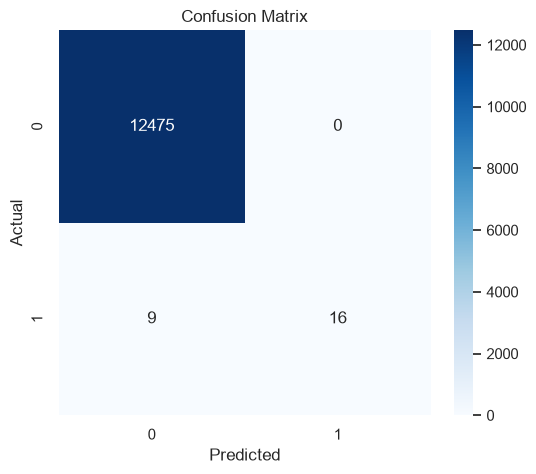

In [43]:
rf_model = RandomForestClassifier(
  n_estimators=2500,
  min_samples_split=6,
  min_samples_leaf=3,
  max_features='sqrt',
  bootstrap=True,
  random_state=RANDOM_STATE,
  class_weight={0: 1.01, 1: 0.98},
)

rf_model.fit(X_train, y_train)
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
conf_matrix = confusion_matrix(y_test, y_test_pred)
class_report = classification_report(y_test, y_test_pred)

print(f'Train Accuracy: {train_accuracy:.4f}')
print(f'Test Accuracy; {test_accuracy:.4f}')

print('\nConfusionMatrix:')
print(conf_matrix)

print('\nClassification Report:')
print(class_report)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()




In [44]:
df_comparison = pd.DataFrame({'True Label': y_test, 'Predicted Label' : y_test_pred})
df_comparison['Correct Prediction']= (df_comparison['True Label'] == df_comparison['Predicted Label']).astype(int)
df_comparison.head()

,True Label,Predicted Label,Correct Prediction
20694,0,0,1
14936,0,0,1
40533,0,0,1
25403,0,0,1
49609,0,0,1


Save Model

In [51]:
joblib.dump(rf_model, 'randomforestmodel.pkl')
joblib.dump(label_encoder, 'label_encoder.pkl')
joblib.dump(scaler, 'X_Scaled.pkl')

['X_Scaled.pkl']